# Fase 4 — Síntesis: trazabilidad texto → u → imagen → clasificador

**Propósito.** Reunir en un solo lugar la cadena de evidencia del proyecto, sin cálculos estadísticos nuevos:
- texto (BETO, 768D);
- **u** (techo 5D; LogReg sobre **u**);
- imagen (LogReg sobre **û** recuperado de la imagen);
- clasificador visual (finalista, media de 5 semillas).

Junto a esa cadena, los análisis explicativos de la Fase 4 (F4.1–F4.8).

**Fuentes.**
- Toda cifra se lee de `results/canonical_numbers.json`, o de un `resultados.json` que las canónicas registran en `inputs`; en ese caso se verifica su sha256 (normalizado a LF) antes de usarlo.
- Las figuras se comprueban con `assert` contra las claves canónicas.
- Excepciones, verificadas por otra vía (sección 0):
  - imágenes de val: sha256 contra `meta/data_manifest.csv`;
  - `medias_clase.npz` de F4.3: sha256 registrado en `results/f43_atribucion/local/resultados.json`;
  - **u**: `umap_params.pkl`, contra el manifiesto, solo para dibujar distribuciones de F4.2;
  - `results/f48_figura/recorridos.json`: F4.8 no tiene claves canónicas; se compara con el blob versionado en HEAD.
- Prueba solo aparece a través de cifras ya archivadas (F5, F4.1, F4.6); no hay inferencia nueva.

**Regla de lectura de la Fase 5** (`docs/bitacora/F5.md`, H2).
- Que el IC de una etapa contenga 0 significa que **no se detecta pérdida**, no que se demuestre que no la hay.
- V1 (conservación) indica que la imagen conserva al menos la mitad de la capacidad discriminativa de BETO por encima del azar. **No es equivalencia con BETO.**

In [1]:
%matplotlib inline
import hashlib
import json
import os
import re
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

T0 = time.time()
REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src', REPO / 'src' / 'training'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style

style.apply()
OUT = REPO / 'results' / 'fase4_sintesis'
FIG = OUT / 'figures'
CANON_DOC = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))
N, INPUTS = CANON_DOC['numbers'], CANON_DOC['inputs']
TECHS = ('gray_scott', 'perlin', 'lorenz')
LBL = style.TECH_LABEL
FIGS, CHECKS = [], []


def cv(nid, split='test'):
    v = N[nid]['value']
    return v[split] if isinstance(v, dict) else v


def ident(prefix):
    ks = [k[len(prefix) + 1:] for k in N if k.startswith(prefix + '.')]
    assert len(ks) == 1, (prefix, ks)
    assert N[f'{prefix}.{ks[0]}']['value'] == 1
    return ks[0]


def sha_lf(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b'\r\n', b'\n')).hexdigest()


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def leer_registrado(rel):
    # resultados.json registrado en canonical_numbers.json:inputs, con su sha256 (LF) verificado
    assert INPUTS[rel] == sha_lf(REPO / rel), rel
    CHECKS.append({'comprobación': f'sha256 (LF) de {rel} = canonical_numbers.json:inputs', 'resultado': 'OK'})
    return json.loads((REPO / rel).read_text(encoding='utf-8'))


def check(desc, cond):
    assert cond, desc
    CHECKS.append({'comprobación': desc, 'resultado': 'OK'})


def guardar(fig, nombre, descripcion, fuentes):
    path = style.save(fig, FIG / nombre)
    FIGS.append({'archivo': path.relative_to(REPO).as_posix(), 'figura': descripcion, 'fuentes': fuentes})
    plt.show()


def pie(fig, text, y=-0.01):
    fig.text(0.01, y, text, ha='left', va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY, wrap=True)


def estado_ic(lo, hi, cero=0.0):
    return 'IC contiene 0' if lo <= cero <= hi else ('IC sobre 0' if lo > cero else 'IC bajo 0')

## 0. Procedencia: commits, insumos y verificaciones

In [2]:
def git(*a):
    return subprocess.run(['git', *a], cwd=REPO, capture_output=True, text=True).stdout.strip()

R41V = leer_registrado('results/f41_recuperabilidad/val/resultados_val.json')
R41T = leer_registrado('results/f41_recuperabilidad/prueba/resultados_prueba.json')
R42 = leer_registrado('results/f42_regimen/resultados.json')
R43 = leer_registrado('results/f43_atribucion/local/resultados.json')
R44 = leer_registrado('results/f44_convergencia/resultados.json')
R5 = leer_registrado('results/f5_contraste/resultados.json')
PRINCIPAL = {t: next(b for b, x in R41V['resultados']['tecnicas'][t].items() if isinstance(x, dict) and x.get('principal'))
             for t in TECHS}
check('backbone principal de F4.1 coincide con el de la condición 2 de F4.6 (nota canónica)',
      'efficientnet_b0_finetune_seed42' in N['f41.prueba.gray_scott.condicion_2_f46']['note']
      and PRINCIPAL['gray_scott'] == 'efficientnet_b0_finetune_seed42')
FUENTES = pd.DataFrame([
    ('HEAD de este notebook', git('rev-parse', 'HEAD')),
    ('F5 (resultados.json:meta.git_commit)', R5['meta'].get('git_commit')),
    ('F4.1 val / prueba', f"{R41V['meta'].get('git_commit')} / {R41T['meta'].get('git_commit')}"),
    ('F4.2', R42['meta']['git_commit']), ('F4.3 (parte local)', R43['meta']['git_commit']),
    ('F4.4', R44['meta']['git_commit']),
    ('Backbone principal de F4.1', json.dumps(PRINCIPAL)),
    ('Claves usadas (prefijos)', 'ref.*, f12.umbral_f1_visual, f35.*, f5.principal.*, f5.sensibilidad.*, f5.descomposicion.*, '
                                 'f5.longitud.*, f41.*, f42.*, f43.*, f44.*, f46.contencion.*, f47.*'),
], columns=['fuente', 'valor'])
pd.set_option('display.max_colwidth', 140)
FUENTES

,fuente,valor
0,HEAD de este notebook,f7183f38bcac1698fc0a317c830a55f939e10a3c
1,F5 (resultados.json:meta.git_commit),dd2e462ca7d2f40326392da6997916a34c7c3606
2,F4.1 val / prueba,e9959df13a842ef3d0107bf7d6cc2c2917e32a37 / a5d13c0709f49738637a60f92845ff88a48057fb
3,F4.2,43ba00a9549c1ee9c972a544d3385871593854a6
4,F4.3 (parte local),95813042a618ae3097bec3a80aef8683004475d4
5,F4.4,ff1654c25cb86f06d2a3a0c9d0c0b985e15b0559
6,Backbone principal de F4.1,"{""gray_scott"": ""efficientnet_b0_finetune_seed42"", ""perlin"": ""vit_b16_imagenet"", ""lorenz"": ""vit_b16_imagenet""}"
7,Claves usadas (prefijos),"ref.*, f12.umbral_f1_visual, f35.*, f5.principal.*, f5.sensibilidad.*, f5.descomposicion.*, f5.longitud.*, f41.*, f42.*, f43.*, f44.*, f..."


## 1. Figura central: la cadena por etapa (F1-Test)

Una fila por técnica. Las etapas son:
- BETO;
- 768D (LogReg sobre el *embedding*);
- techo 5D (SVM-RBF sobre **u**);
- LogReg sobre **u** (F4.1);
- LogReg sobre **û** (F4.1, *backbone* principal);
- finalista visual (media de las 5 semillas).

Diferencias con IC al 95 %:
- **F5.3 (descomposición):** cabeza = BETO − 768D; reducción = 768D − techo 5D; renderizado = techo 5D − visual.
- **F4.1:** ΔF1 = F1(**u**) − F1(**û**).

La línea discontinua es el umbral equivalente `f12.umbral_f1_visual`.

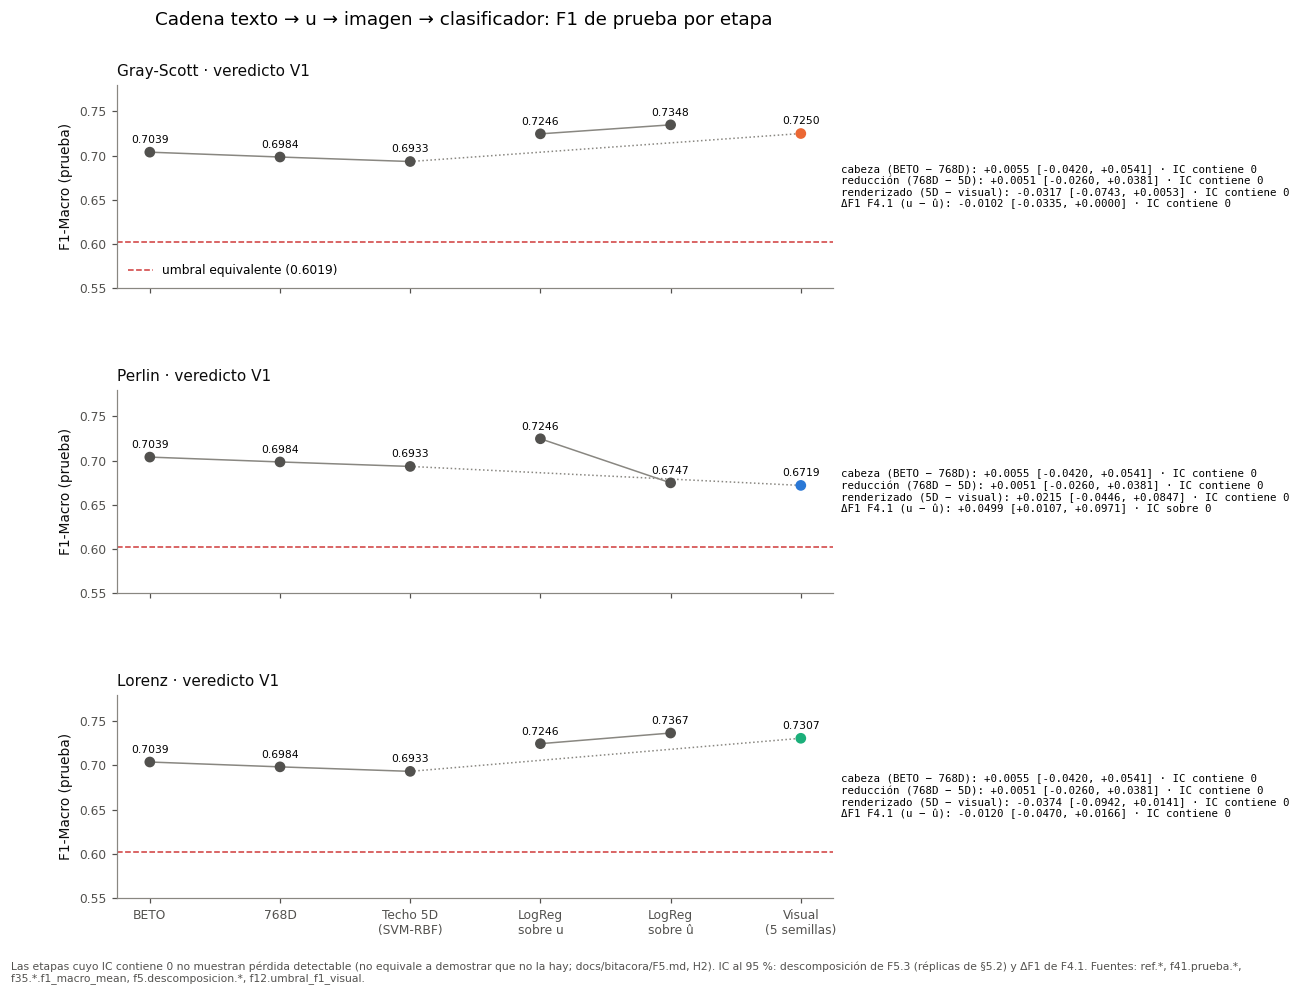

,técnica,etapa,Δ,IC inf,IC sup,estado
0,Gray-Scott,cabeza (BETO − 768D),0.005483,-0.041969,0.054088,IC contiene 0
1,Gray-Scott,reducción (768D − 5D),0.005089,-0.025958,0.038089,IC contiene 0
2,Gray-Scott,renderizado (5D − visual),-0.031674,-0.074282,0.005263,IC contiene 0
3,Gray-Scott,ΔF1 F4.1 (u − û),-0.010182,-0.033510,0.000000,IC contiene 0
4,Perlin,cabeza (BETO − 768D),0.005483,-0.041969,0.054088,IC contiene 0
5,Perlin,reducción (768D − 5D),0.005089,-0.025958,0.038089,IC contiene 0
6,Perlin,renderizado (5D − visual),0.021454,-0.044563,0.084733,IC contiene 0
7,Perlin,ΔF1 F4.1 (u − û),0.049901,0.010660,0.097141,IC sobre 0
8,Lorenz,cabeza (BETO − 768D),0.005483,-0.041969,0.054088,IC contiene 0
9,Lorenz,reducción (768D − 5D),0.005089,-0.025958,0.038089,IC contiene 0


In [3]:
ETAPAS = ['BETO', '768D', 'Techo 5D\n(SVM-RBF)', 'LogReg\nsobre u', 'LogReg\nsobre û', 'Visual\n(5 semillas)']
umbral = cv('f12.umbral_f1_visual')
fig, axes = plt.subplots(3, 1, figsize=(8.4, 9.6), sharex=True, gridspec_kw={'hspace': 0.5})
CADENA = {}
check('techo 5D = SVM-RBF (ref.techo5d = ref.techo5d.svm_rbf)', cv('ref.techo5d.f1_macro') == cv('ref.techo5d.svm_rbf.f1_macro'))
for ax, t in zip(axes, TECHS):
    b = PRINCIPAL[t]
    f1 = [cv('ref.beto_exp41.f1_macro'), cv('ref.emb768_logreg.f1_macro'), cv('ref.techo5d.f1_macro'),
          cv('f41.prueba.u.logreg.f1_macro'), cv(f'f41.prueba.{t}.{b}.logreg_u_hat.f1_macro'),
          cv(f'f35.{t}.finalista.f1_macro_mean')]
    D = f'f5.descomposicion.{t}'
    etapas = {'cabeza (BETO − 768D)': (D + '.cabeza', f1[0] - f1[1]),
              'reducción (768D − 5D)': (D + '.reduccion', f1[1] - f1[2]),
              'renderizado (5D − visual)': (D + '.renderizado', f1[2] - f1[5]),
              'ΔF1 F4.1 (u − û)': (f'f41.prueba.{t}.{b}.delta_f1', f1[3] - f1[4])}
    filas = []
    for nombre, (k, dif) in etapas.items():
        v, lo, hi = cv(k), cv(k + '_ic_inf'), cv(k + '_ic_sup')
        check(f'{t}: {nombre} = diferencia de los F1 graficados ({k})', abs(v - dif) < 1e-9)
        filas.append((nombre, v, lo, hi, estado_ic(lo, hi)))
    CADENA[t] = {'f1': f1, 'etapas': filas}
    x = np.arange(len(f1))
    ax.axhline(umbral, color=style.THRESHOLD_COLOR, ls='--', lw=1, label=f'umbral equivalente ({umbral:.4f})')
    ax.plot(x[:3], f1[:3], color=style.MUTED, lw=1)
    ax.plot([2, 5], [f1[2], f1[5]], color=style.MUTED, lw=1, ls=':')
    ax.plot([3, 4], f1[3:5], color=style.MUTED, lw=1)
    cols = [style.INK_SECONDARY] * 5 + [style.TECH_COLOR[t]]
    ax.scatter(x, f1, c=cols, s=36, zorder=3)
    for xi, yi in zip(x, f1):
        ax.annotate(f'{yi:.4f}', (xi, yi), xytext=(0, 6), textcoords='offset points', ha='center',
                    fontsize=style.FONT_SIZES['annot'])
    txt = '\n'.join(f'{n}: {v:+.4f} [{lo:+.4f}, {hi:+.4f}] · {e}' for n, v, lo, hi, e in filas)
    ax.text(1.01, 0.5, txt, transform=ax.transAxes, va='center', fontsize=style.FONT_SIZES['annot'], family='monospace')
    ax.set_ylim(0.55, 0.78)
    ax.set_ylabel('F1-Macro (prueba)')
    ax.set_title(f'{LBL[t]} · veredicto {ident(f"f5.principal.{t}.veredicto").upper()}', loc='left')
axes[0].legend(loc='lower left')
axes[-1].set_xticks(range(len(ETAPAS)))
axes[-1].set_xticklabels(ETAPAS)
fig.suptitle('Cadena texto → u → imagen → clasificador: F1 de prueba por etapa', y=0.95)
pie(fig, 'Las etapas cuyo IC contiene 0 no muestran pérdida detectable (no equivale a demostrar que no la hay; '
         'docs/bitacora/F5.md, H2). IC al 95 %: descomposición de F5.3 (réplicas de §5.2) y ΔF1 de F4.1. '
         'Fuentes: ref.*, f41.prueba.*, f35.*.f1_macro_mean, f5.descomposicion.*, f12.umbral_f1_visual.', y=0.05)
guardar(fig, 'fase4_01_cadena_por_etapa', 'Cadena por etapa: F1 de prueba de BETO, 768D, techo 5D, LogReg sobre u y û, y visual, con IC por etapa',
        'ref.*, f41.prueba.*, f35.*, f5.descomposicion.*, f12.umbral_f1_visual')
pd.DataFrame([{'técnica': LBL[t], 'etapa': n, 'Δ': v, 'IC inf': lo, 'IC sup': hi, 'estado': e}
              for t in TECHS for n, v, lo, hi, e in CADENA[t]['etapas']])

## 2. Tabla de evidencia (técnica × análisis)

Derivada de las claves canónicas. Cada celda lleva el valor y un estado textual tomado de las reglas ya fijadas (plan de la Fase 4, protocolo); no hay juicios nuevos.

In [4]:
def sens_f5(t):
    ppal = ident(f'f5.principal.{t}.veredicto')
    otros = []
    for k in sorted(N):
        m = re.match(rf'f5\.sensibilidad\.(.+)\.{t}\.veredicto\.(v\d)$', k)
        if m and m.group(2) != ppal:
            otros.append(f'{m.group(2).upper()} en {m.group(1)}')
    return ppal.upper(), ('igual en todas las variantes' if not otros else '; '.join(otros))


NOM_D = {'shannon_entropy': 'entropía', 'contrast': 'contraste', 'edge_density': 'bordes', 'lbp_energy': 'LBP'}
EVID = {}
for t in TECHS:
    b = PRINCIPAL[t]
    ppal, sens = sens_f5(t)
    th = f'f5.principal.{t}.theta'
    r2 = {f'u{i}': cv(f'f41.prueba.{t}.{b}.r2.u{i}') for i in range(5)}
    d41 = f'f41.prueba.{t}.{b}.delta_f1'
    dl, dh = cv(d41 + '_ic_inf'), cv(d41 + '_ic_sup')
    check(f'{t}: ic_contiene_0 de F4.1 coincide con el IC', N[d41 + '.ic_contiene_0']['value'] == int(dl <= 0 <= dh))
    if t == 'gray_scott':
        f42 = (f"reintentos por clase: Fisher p_holm = {cv('f42.gray_scott.fisher_reintentos.p_holm', 'train'):.3g} "
               f"(rechaza = {N['f42.gray_scott.fisher_reintentos.holm.rechaza']['value']}); (f, k): descriptivo, sin prueba")
    elif t == 'perlin':
        f42 = (f"octavas: Mann–Whitney p_holm = {cv('f42.perlin.mw_octavas.p_holm', 'train'):.3g} "
               f"(rechaza = {N['f42.perlin.mw_octavas.holm.rechaza']['value']})")
    else:
        f42 = (f"ρ < 24.74: Fisher p_holm = {cv('f42.lorenz.fisher_regimen.p_holm', 'train'):.3g}; "
               f"ρ: Mann–Whitney p_holm = {cv('f42.lorenz.mw_rho.p_holm', 'train'):.3g} (rechazan = "
               f"{N['f42.lorenz.fisher_regimen.holm.rechaza']['value']}, {N['f42.lorenz.mw_rho.holm.rechaza']['value']}); "
               f"{N['f42.lorenz.rho_menor_24_74.n.dep']['value'] + N['f42.lorenz.rho_menor_24_74.n.nodep']['value']} de "
               f"{N['f42.n_train.total']['value']} bajo 24.74")
    cd = ident(f'f43.{t}.cordura_datos.map.veredicto')
    cab = ident(f'f43.{t}.cascada.cabeza.map.veredicto')
    lect = ident(f'f43.{t}.lectura_vit') if t != 'gray_scott' else None
    f43 = f'datos: {cd}; cascada (cabeza): {cab}' + (f'; lectura ViT: {lect}' if lect else '') + \
          ('; no validado por datos' if cd == 'no_cambia' else '')
    abl = {(bd, s): cv(f'f43.{t}.ablacion.{bd}.s{s}.delta_f1', 'val') for bd in ('paso_bajo', 'paso_alto') for s in (1, 2, 4, 8)}
    (bd, s), v = min(abl.items(), key=lambda kv: kv[1])
    f43b = f'mayor descenso: {bd.replace("_", "-")} σ = {s}, ΔF1 = {v:+.4f} (descriptivo)'
    f44 = '; '.join(f"{NOM_D[d]} {cv(f'f44.{t}.{d}.spearman_media', 'val'):+.3f} "
                    f"({estado_ic(cv(f'f44.{t}.{d}.spearman_media_ic_inf', 'val'), cv(f'f44.{t}.{d}.spearman_media_ic_sup', 'val'))})"
                    for d in R44['resultados']['spearman'][t]['map'])
    C46 = f'f46.contencion.{t}.techo5d'
    c1, c2 = N[f'f46.contencion.{t}.condicion_1']['value'], N[f'f41.prueba.{t}.condicion_2_f46']['value']
    frase = ('«consistente con que el visual hereda los errores de u»' if c1 and c2 else
             'errores concentrados en los de u más de lo esperado por independencia (falla la condición 2)' if c1 else
             'sin evidencia de concentración')
    EVID[LBL[t]] = {
        'F5: veredicto (θ, IC)': f"{ppal} (θ = {cv(th):.4f} [{cv(th + '_ic_inf'):.4f}, {cv(th + '_ic_sup'):.4f}])",
        'F5: sensibilidad': sens,
        'F4.5: longitud': f"L = {cv(f'f5.longitud.{t}.l'):.4f}; p = {cv(f'f5.longitud.{t}.p'):.4g}; Holm rechaza = {N[f'f5.longitud.{t}.rechaza']['value']} (1 = supera al clasificador de longitud; docs/bitacora/F4.5.md, H1)",
        'F4.1: R² (prueba, principal)': ', '.join(f'{k} {v:.3f}' for k, v in r2.items()),
        'F4.1: ΔF1 u − û': f"{cv(d41):+.4f} [{dl:+.4f}, {dh:+.4f}]; {estado_ic(dl, dh)}",
        'F4.7: Mantel ρ (train)': f"ρ = {cv(f'f47.{t}.rho_spearman', 'train'):.4f}; Holm rechaza = {N[f'f47.{t}.holm.rechaza']['value']}",
        'F4.2: parámetros y régimen (train)': f42,
        'F4.3: cordura de los mapas': f43,
        'F4.3: banda (ablación, val)': f43b,
        'F4.4: convergencia (Spearman, val)': f44 + ('; mapas sin validación por datos (F4.3)' if lect and 'sin_validacion' in lect else ''),
        'F4.6: contención frente al techo': f"C = {cv(C46 + '.c'):.4f} [{cv(C46 + '.c_ic_inf'):.4f}, {cv(C46 + '.c_ic_sup'):.4f}]; "
                                            f"nula = {cv(C46 + '.nula'):.4f}; {frase}",
    }
TABLA = pd.DataFrame(EVID)
OUT.mkdir(parents=True, exist_ok=True)
TABLA.to_csv(OUT / 'tabla_evidencia.csv', encoding='utf-8', lineterminator='\n')
TABLA

,Gray-Scott,Perlin,Lorenz
"F5: veredicto (θ, IC)","V1 (θ = 0.1230 [0.0688, 0.1738])","V1 (θ = 0.0699 [0.0246, 0.1128])","V1 (θ = 0.1288 [0.0720, 0.1819])"
F5: sensibilidad,igual en todas las variantes,V4 en formulacion_a.r0_75; V4 en formulacion_a.r0_80; V4 en por_semilla.seed2024; V4 en por_semilla.seed42; V4 en retencion_exigida.r0_7...,igual en todas las variantes
F4.5: longitud,"L = 0.2108; p = 0.0001; Holm rechaza = 1 (1 = supera al clasificador de longitud; docs/bitacora/F4.5.md, H1)","L = 0.1577; p = 0.0029; Holm rechaza = 1 (1 = supera al clasificador de longitud; docs/bitacora/F4.5.md, H1)","L = 0.2165; p = 0.0001; Holm rechaza = 1 (1 = supera al clasificador de longitud; docs/bitacora/F4.5.md, H1)"
"F4.1: R² (prueba, principal)","u0 0.968, u1 0.861, u2 0.939, u3 0.862, u4 0.965","u0 0.949, u1 0.756, u2 0.951, u3 0.853, u4 0.914","u0 0.929, u1 0.614, u2 0.925, u3 0.873, u4 0.992"
F4.1: ΔF1 u − û,"-0.0102 [-0.0335, +0.0000]; IC contiene 0","+0.0499 [+0.0107, +0.0971]; IC sobre 0","-0.0120 [-0.0470, +0.0166]; IC contiene 0"
F4.7: Mantel ρ (train),ρ = 0.8019; Holm rechaza = 1,ρ = 0.5221; Holm rechaza = 1,ρ = 0.3191; Holm rechaza = 1
F4.2: parámetros y régimen (train),"reintentos por clase: Fisher p_holm = 6.08e-06 (rechaza = 1); (f, k): descriptivo, sin prueba",octavas: Mann–Whitney p_holm = 1.05e-106 (rechaza = 1),"ρ < 24.74: Fisher p_holm = 0.00306; ρ: Mann–Whitney p_holm = 1.65e-13 (rechazan = 1, 1); 19 de 908 bajo 24.74"
F4.3: cordura de los mapas,datos: cambia; cascada (cabeza): cambia,datos: cambia; cascada (cabeza): cambia; lectura ViT: cordura_por_datos_superada,datos: no_cambia; cascada (cabeza): cambia; lectura ViT: dependiente_de_la_cabeza_sin_validacion_por_datos; no validado por datos
"F4.3: banda (ablación, val)","mayor descenso: paso-bajo σ = 8, ΔF1 = -0.2615 (descriptivo)","mayor descenso: paso-bajo σ = 4, ΔF1 = -0.1595 (descriptivo)","mayor descenso: paso-alto σ = 1, ΔF1 = -0.2815 (descriptivo)"
"F4.4: convergencia (Spearman, val)",entropía +0.023 (IC contiene 0); contraste -0.038 (IC contiene 0); bordes +0.039 (IC contiene 0); LBP -0.016 (IC contiene 0),contraste +0.412 (IC sobre 0); bordes +0.013 (IC contiene 0),entropía +0.648 (IC sobre 0); LBP -0.647 (IC bajo 0); mapas sin validación por datos (F4.3)


## 3. Fichas por técnica

Cada ficha reúne seis paneles: ejemplos de imágenes de val por clase (3 y 3, del conjunto almacenado); R² por componente (F4.1, *backbone* principal, val y prueba); diferencia de mapas medios por clase (F4.3, val); ΔF1 de la ablación por banda (F4.3, val); distribución del parámetro que separa las clases (F4.2, train); Spearman de convergencia (F4.4, val).

In [5]:
assert os.environ.get('TT_DATA_ROOT'), 'TT_DATA_ROOT no definida'
from src.fase4 import convergencia as conv
from src.fase4 import atribucion_local as al
from src.fase4.regimen import load_u
import gray_scott_lib as gsl
import lorenz_lib as lzl
import perlin_lib as pnl
%matplotlib inline

MED = REPO / 'results' / 'f43_atribucion' / 'local' / 'medias_clase.npz'
check('sha256 de medias_clase.npz = resultados.json de F4.3 (meta.medias_clase_sha256)', sha(MED) == R43['meta']['medias_clase_sha256'])
MED = np.load(MED)
IDX = al.load_index()
U = load_u(IDX, ('train',))
u_tr, y_tr = U['train']
IMGS = {}
for t in TECHS:
    im, ids, huella = conv.cargar_imagenes_val(t)
    IMGS[t] = (im, ids)
    check(f'{t}: huella de las imágenes de val = la registrada en F4.4', huella == R44['meta']['imagenes_val_sha256_lista'][t])
Y_VAL = np.array([int(r['y_true']) for r in IDX['val']])

# Parámetro que separa las clases (F4.2), recalculado desde u solo para dibujar y comprobado contra resultados.json
f_gs = np.array([gsl.umap_to_rd_params(u)['f'] for u in u_tr])
oct_p = np.array([pnl.map_umap_to_perlin(u)['n_octaves'] for u in u_tr])
rho_l = np.array([lzl.map_umap_to_lorenz(u)['rho'] for u in u_tr])
G = R42['resultados']
for cl, y in (('dep', 1), ('nodep', 0)):
    check(f'F4.2 Gray-Scott: media de f ({cl}) = resultados.json', abs(f_gs[y_tr == y].mean() - G['gray_scott']['fk_por_clase'][cl]['f_media']) < 1e-12)
    check(f'F4.2 Lorenz: mediana de ρ ({cl}) = resultados.json', abs(np.median(rho_l[y_tr == y]) - G['pruebas']['lorenz_mw_rho'][f'mediana_{cl}']) < 1e-6)
    check(f'F4.2 Lorenz: n con ρ < 24.74 ({cl}) = f42.lorenz.rho_menor_24_74.n.{cl}',
          int((rho_l[y_tr == y] < 24.74).sum()) == N[f'f42.lorenz.rho_menor_24_74.n.{cl}']['value'])
    for o in range(1, 9):
        assert int((oct_p[y_tr == y] == o).sum()) == G['perlin']['octavas_por_clase'][str(o)][cl]
check('F4.2 Perlin: conteos de octavas por clase = resultados.json', True)

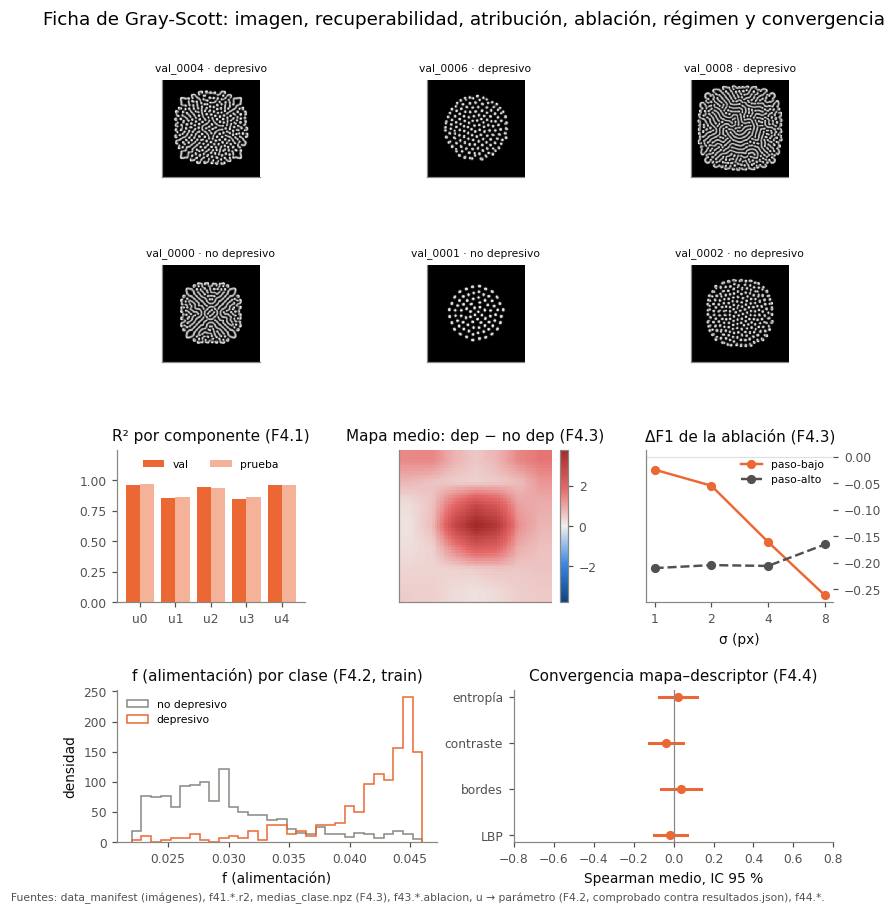

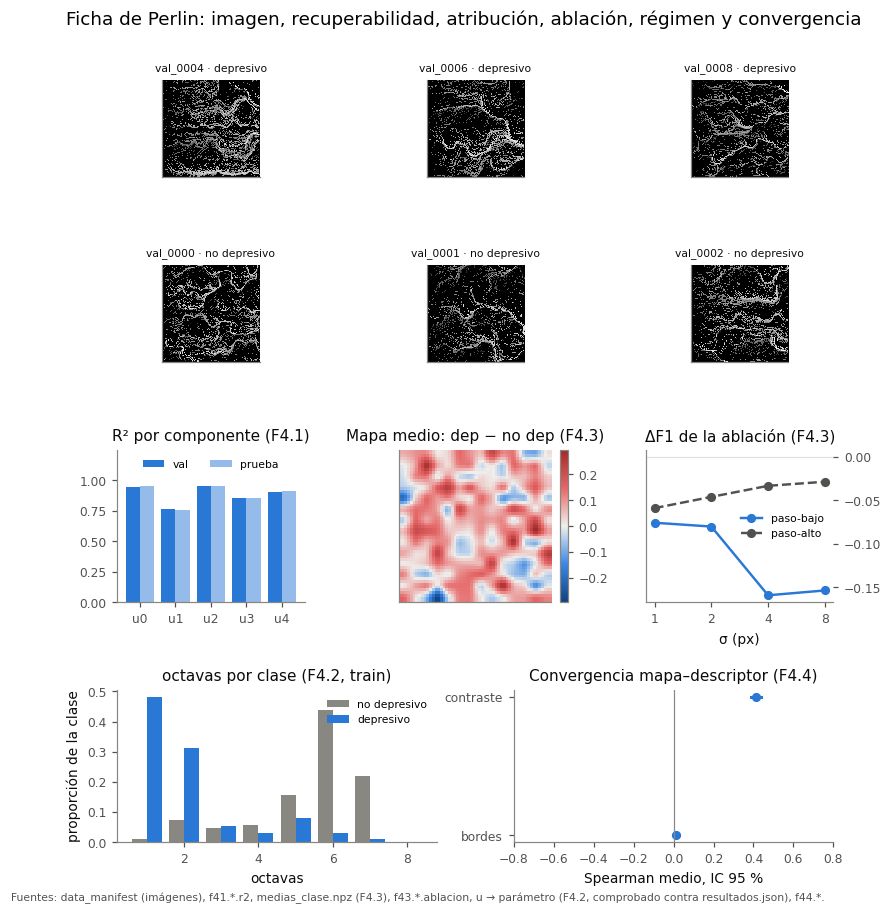

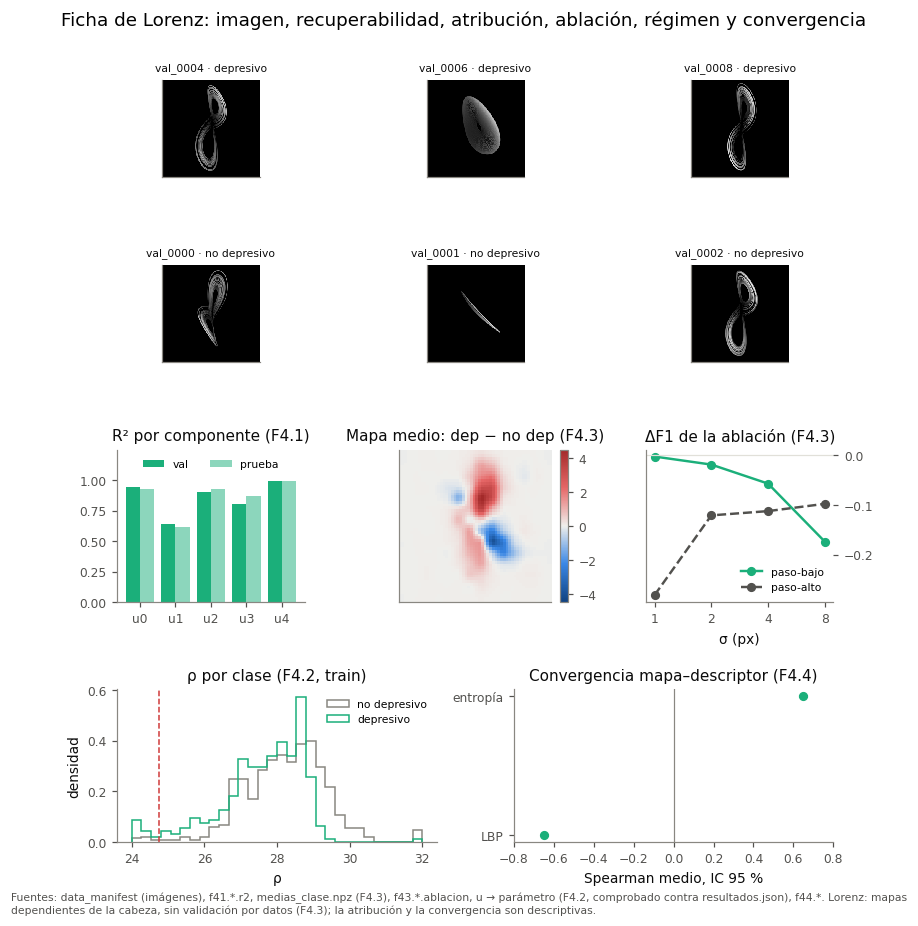

In [6]:
PARAM = {'gray_scott': ('f (alimentación)', f_gs, 'f42.gray_scott.fisher_reintentos (reintentos); f descriptivo'),
         'perlin': ('octavas', oct_p, 'f42.perlin.mw_octavas'),
         'lorenz': ('ρ', rho_l, 'f42.lorenz.mw_rho y fisher_regimen')}
COL = {0: style.MUTED, 1: None}


def ficha(t, n_fig):
    col = style.TECH_COLOR[t]
    fig = plt.figure(figsize=(8.4, 9.0))
    gs = fig.add_gridspec(4, 6, height_ratios=[0.8, 0.8, 1.25, 1.25], hspace=0.7, wspace=1.4)
    im, ids = IMGS[t]
    for c, y in ((0, 1), (1, 0)):
        sel = np.flatnonzero(Y_VAL == y)[:3]
        for j, i in enumerate(sel):
            ax = fig.add_subplot(gs[c, 2 * j:2 * j + 2])
            ax.imshow(im[i], cmap='gray', vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{ids[i]} · {'depresivo' if y else 'no depresivo'}", fontsize=style.FONT_SIZES['annot'])
    # R²
    ax = fig.add_subplot(gs[2, 0:2])
    b = PRINCIPAL[t]
    rv = [cv(f'f41.val.{t}.{b}.r2.u{i}', 'val') for i in range(5)]
    rt = [cv(f'f41.prueba.{t}.{b}.r2.u{i}') for i in range(5)]
    x = np.arange(5)
    ax.bar(x - 0.2, rv, 0.4, color=col, label='val')
    ax.bar(x + 0.2, rt, 0.4, color=col, alpha=0.5, label='prueba')
    ax.set_xticks(x); ax.set_xticklabels([f'u{i}' for i in range(5)])
    ax.set_ylim(0, 1.25); ax.set_yticks([0, 0.25, 0.5, 0.75, 1]); ax.set_title('R² por componente (F4.1)'); ax.legend(fontsize=style.FONT_SIZES['annot'], ncol=2, loc='upper center')
    # Mapas medios: diferencia
    ax = fig.add_subplot(gs[2, 2:4])
    d = MED[f'{t}|map|val|real|y1'] - MED[f'{t}|map|val|real|y0']
    lim = np.abs(d).max()
    h = ax.imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(h, ax=ax, fraction=0.046)
    ax.set_title('Mapa medio: dep − no dep (F4.3)')
    # Ablación
    ax = fig.add_subplot(gs[2, 4:6])
    for bd, ls in (('paso_bajo', '-'), ('paso_alto', '--')):
        ax.plot([1, 2, 4, 8], [cv(f'f43.{t}.ablacion.{bd}.s{s}.delta_f1', 'val') for s in (1, 2, 4, 8)], ls=ls, marker='o',
                color=col if bd == 'paso_bajo' else style.INK_SECONDARY, label=bd.replace('_', '-'))
    ax.axhline(0, color=style.GRID, lw=0.8)
    ax.set_xscale('log', base=2); ax.set_xticks([1, 2, 4, 8]); ax.set_xticklabels([1, 2, 4, 8])
    ax.yaxis.tick_right()
    ax.set_xlabel('σ (px)'); ax.set_title('ΔF1 de la ablación (F4.3)'); ax.legend(fontsize=style.FONT_SIZES['annot'])
    # Parámetro F4.2
    ax = fig.add_subplot(gs[3, 0:3])
    nombre, v, _ = PARAM[t]
    if t == 'perlin':
        for y, dx in ((0, -0.2), (1, 0.2)):
            cnt = np.array([(v[y_tr == y] == o).sum() for o in range(1, 9)]) / (y_tr == y).sum()
            ax.bar(np.arange(1, 9) + dx, cnt, 0.4, color=col if y else style.MUTED, label='depresivo' if y else 'no depresivo')
        ax.set_ylabel('proporción de la clase')
    else:
        bins = np.linspace(v.min(), v.max(), 31)
        for y in (0, 1):
            ax.hist(v[y_tr == y], bins=bins, density=True, histtype='step', lw=1.6, color=col if y else style.MUTED,
                    label='depresivo' if y else 'no depresivo')
        if t == 'lorenz':
            ax.axvline(24.74, color=style.THRESHOLD_COLOR, ls='--', lw=1)
        ax.set_ylabel('densidad')
    ax.set_xlabel(nombre); ax.set_title(f'{nombre} por clase (F4.2, train)'); ax.legend(fontsize=style.FONT_SIZES['annot'])
    # Convergencia F4.4
    ax = fig.add_subplot(gs[3, 3:6])
    ds = list(R44['resultados']['spearman'][t]['map'])
    m = [cv(f'f44.{t}.{d}.spearman_media', 'val') for d in ds]
    lo = [cv(f'f44.{t}.{d}.spearman_media_ic_inf', 'val') for d in ds]
    hi = [cv(f'f44.{t}.{d}.spearman_media_ic_sup', 'val') for d in ds]
    yy = np.arange(len(ds))[::-1]
    for yi, a, l_, h_ in zip(yy, m, lo, hi):
        ax.plot([l_, h_], [yi, yi], color=col, lw=2); ax.plot(a, yi, 'o', color=col)
    ax.axvline(0, color=style.MUTED, lw=0.8)
    ax.set_yticks(yy); ax.set_yticklabels([NOM_D[d] for d in ds]); ax.set_xlim(-0.8, 0.8)
    ax.set_title('Convergencia mapa–descriptor (F4.4)'); ax.set_xlabel('Spearman medio, IC 95 %')
    fig.suptitle(f'Ficha de {LBL[t]}: imagen, recuperabilidad, atribución, ablación, régimen y convergencia', y=0.95)
    aviso = (' Lorenz: mapas dependientes de la cabeza, sin validación por datos (F4.3); la atribución y la convergencia son '
             'descriptivas.' if t == 'lorenz' else '')
    pie(fig, 'Fuentes: data_manifest (imágenes), f41.*.r2, medias_clase.npz (F4.3), f43.*.ablacion, u → parámetro (F4.2, '
             'comprobado contra resultados.json), f44.*.' + aviso, y=0.06)
    guardar(fig, f'fase4_0{n_fig}_ficha_{t}', f'Ficha de {LBL[t]}', 'data_manifest, f41.*, medias_clase.npz, f43.*, F4.2, f44.*')


for n_fig, t in enumerate(TECHS, start=2):
    ficha(t, n_fig)

## 4. Dirección discriminativa (F4.8): coherencia descriptiva, sin peso argumentativo

Una figura por técnica muestra la rejilla de F4.8 (dirección de la LogReg 5D de F2.1, renderizada). Una figura final muestra ŵ por componente y la separación por clase de dos parámetros de F4.2:
- f de Gray-Scott, función de u0;
- las octavas de Perlin, función de u4.

**Esto no sustenta ninguna conclusión** (plan, F4.8): es una coherencia descriptiva entre el signo de ŵ y la dirección en que difieren las clases.

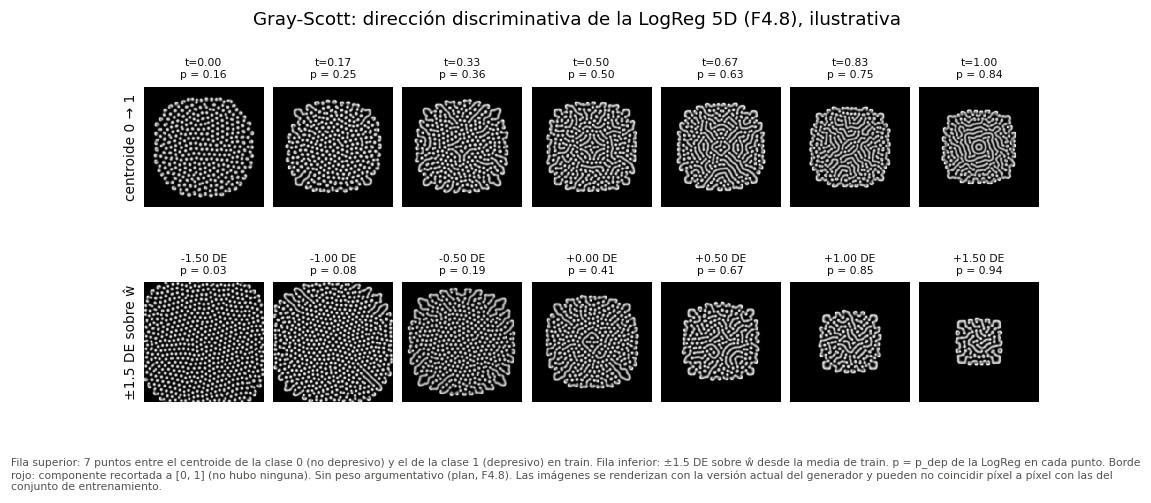

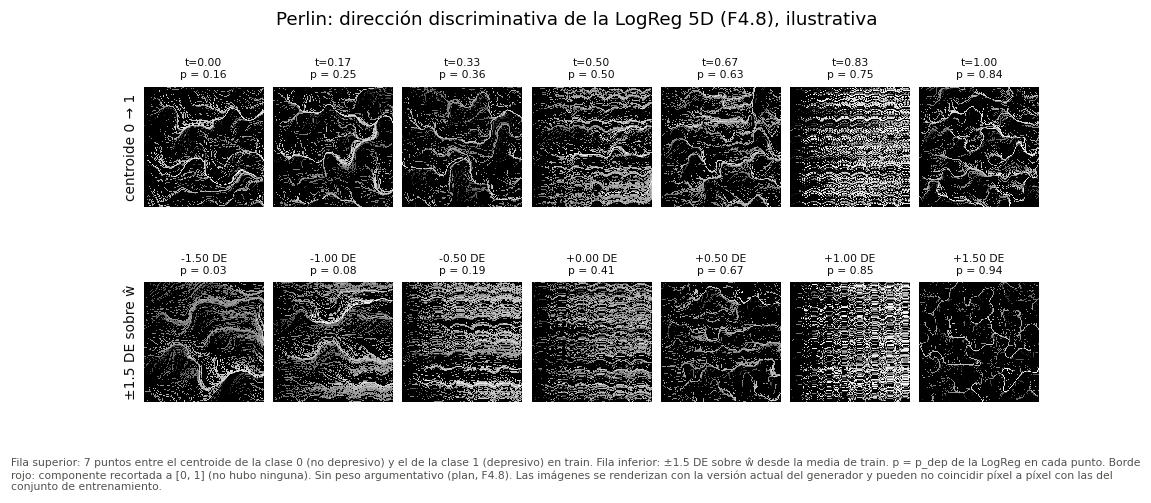

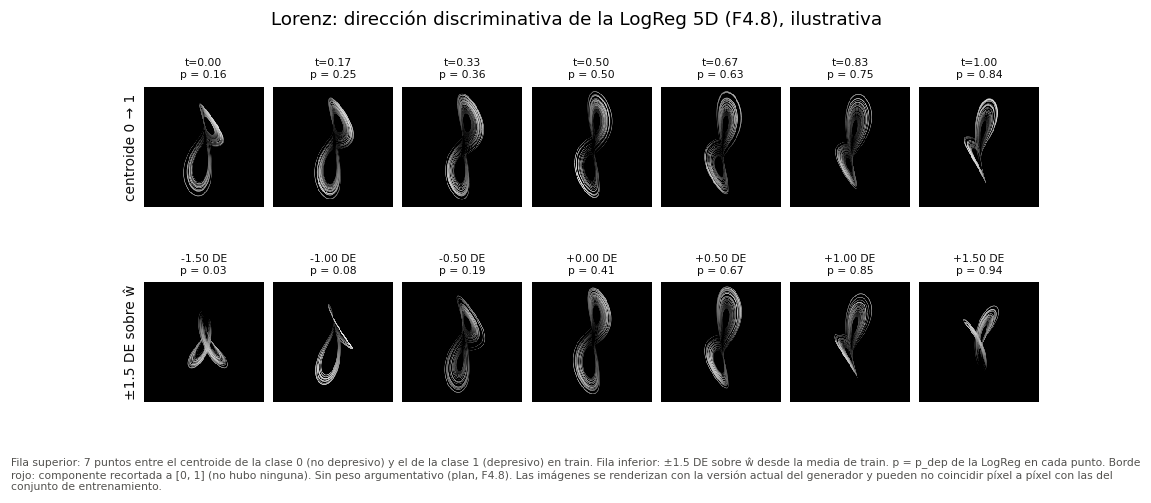

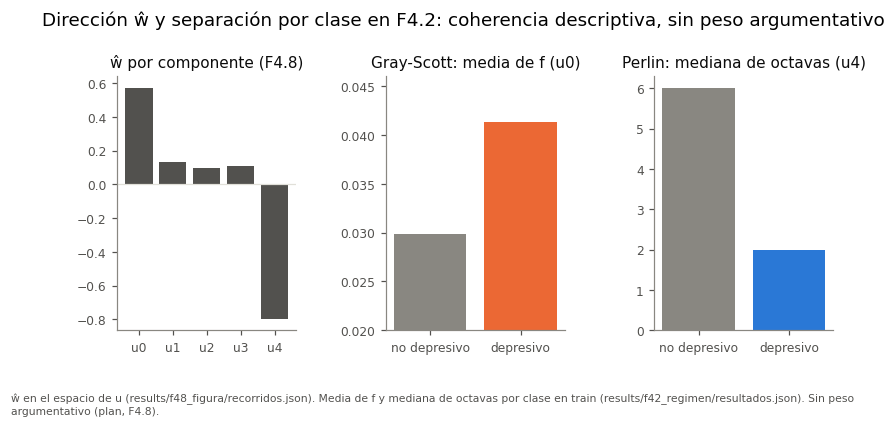

,componente,ŵ
0,u0,0.571919
1,u1,0.133549
2,u2,0.096992
3,u3,0.107051
4,u4,-0.796371


In [7]:
REC = REPO / 'results' / 'f48_figura' / 'recorridos.json'
blob = subprocess.run(['git', 'show', 'HEAD:results/f48_figura/recorridos.json'], cwd=REPO, capture_output=True).stdout
check('recorridos.json de F4.8 = blob versionado en HEAD (F4.8 no tiene claves canónicas)',
      hashlib.sha256(blob.replace(b'\r\n', b'\n')).hexdigest() == sha_lf(REC))
D48 = json.loads(REC.read_text(encoding='utf-8'))
w = np.array(D48['direccion']['w_unitario'])
from PIL import Image as PILImage
IMG48 = REPO / 'results' / 'f48_figura' / 'imagenes'
NOTA48 = ('Sin peso argumentativo (plan, F4.8). Las imágenes se renderizan con la versión actual del generador y pueden no '
          'coincidir píxel a píxel con las del conjunto de entrenamiento.')
RECS = ('centroides', 'direccion')
for t in TECHS:
    rutas = [IMG48 / f'{t}_{r}_{j}.png' for r in RECS for j in range(len(D48['recorridos'][r]['u']))]
    for pth in rutas:
        rel = pth.relative_to(REPO).as_posix()
        b = subprocess.run(['git', 'show', f'HEAD:{rel}'], cwd=REPO, capture_output=True).stdout
        assert hashlib.sha256(b).hexdigest() == sha(pth), rel
    check(f'F4.8 {t}: las {len(rutas)} imágenes = blobs versionados en HEAD', True)
for n_fig, t in enumerate(TECHS, start=5):
    fig, axes = plt.subplots(2, 7, figsize=(10.5, 3.9), gridspec_kw={'hspace': 0.45, 'wspace': 0.08})
    for i, r in enumerate(RECS):
        R_ = D48['recorridos'][r]
        for j, ax in enumerate(axes[i]):
            ax.imshow(np.array(PILImage.open(IMG48 / f'{t}_{r}_{j}.png').convert('L')), cmap='gray', vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            rec = bool(R_['recortado'][j])
            for sp in ax.spines.values():
                sp.set_visible(rec); sp.set_color(style.THRESHOLD_COLOR); sp.set_linewidth(1.6)
            ax.set_title(f"{R_['ticks'][j]}\np = {R_['p_dep_logreg'][j]:.2f}", fontsize=style.FONT_SIZES['annot'])
        axes[i, 0].set_ylabel(R_['etiqueta'], fontsize=style.FONT_SIZES['label'])
    fig.suptitle(f'{LBL[t]}: dirección discriminativa de la LogReg 5D (F4.8), ilustrativa', y=1.04)
    pie(fig, 'Fila superior: 7 puntos entre el centroide de la clase 0 (no depresivo) y el de la clase 1 (depresivo) en train. '
             'Fila inferior: ±1.5 DE sobre ŵ desde la media de train. p = p_dep de la LogReg en cada punto. Borde rojo: '
             'componente recortada a [0, 1] (no hubo ninguna). ' + NOTA48, y=0.0)
    guardar(fig, f'fase4_0{n_fig}_direccion_{t}', f'Dirección discriminativa de F4.8 renderizada con {LBL[t]} (ilustrativa)',
            f'results/f48_figura/imagenes/{t}_*.png, results/f48_figura/recorridos.json')

fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0), gridspec_kw={'wspace': 0.5})
ax = axes[0]
ax.bar(range(5), w, color=[style.INK_SECONDARY] * 5)
ax.axhline(0, color=style.GRID, lw=0.8)
ax.set_xticks(range(5)); ax.set_xticklabels([f'u{i}' for i in range(5)]); ax.set_title('ŵ por componente (F4.8)')
ax = axes[1]
fk = G['gray_scott']['fk_por_clase']
ax.bar([0, 1], [fk['nodep']['f_media'], fk['dep']['f_media']], color=[style.MUTED, style.TECH_COLOR['gray_scott']])
ax.set_xticks([0, 1]); ax.set_xticklabels(['no depresivo', 'depresivo']); ax.set_ylim(0.02, 0.046)
ax.set_title('Gray-Scott: media de f (u0)')
ax = axes[2]
mw = G['pruebas']['perlin_mw_octavas']
ax.bar([0, 1], [mw['mediana_nodep'], mw['mediana_dep']], color=[style.MUTED, style.TECH_COLOR['perlin']])
ax.set_xticks([0, 1]); ax.set_xticklabels(['no depresivo', 'depresivo']); ax.set_title('Perlin: mediana de octavas (u4)')
fig.suptitle('Dirección ŵ y separación por clase en F4.2: coherencia descriptiva, sin peso argumentativo', y=1.08)
pie(fig, 'ŵ en el espacio de u (results/f48_figura/recorridos.json). Media de f y mediana de octavas por clase en train '
         '(results/f42_regimen/resultados.json). Sin peso argumentativo (plan, F4.8).', y=-0.08)
guardar(fig, 'fase4_08_direccion_componentes', 'ŵ por componente (F4.8) y separación por clase de u0 (f) y u4 (octavas) en F4.2',
        'results/f48_figura/recorridos.json, results/f42_regimen/resultados.json')
pd.DataFrame({'componente': [f'u{i}' for i in range(5)], 'ŵ': w})

## 5. Limitaciones consolidadas (citadas de las bitácoras, sin reescribirlas)

In [8]:
CITAS = [('n = 114', 'docs/bitacora/F5.md', '5. **Tamaño de prueba.**'),
         ('Fragilidad de la selección (F3.3)', 'docs/bitacora/F5.md', '2. **Fragilidad de la selección (F3.3, H2).**'),
         ('Piso visual permutado (F3.6, H2)', 'docs/bitacora/F3.6.md', '- *Implicación:* el piso «visual permutado»'),
         ('Perlin con r ≥ 0.75', 'docs/bitacora/F5.md', '- Obtiene V4 en las cuatro variantes con r ≥ 0.75'),
         ('Mapas de Lorenz sin validación por datos (F4.3)', 'docs/bitacora/F4.3.md', '4. **Lorenz sin validación por datos.**'),
         ('Descriptores por parche (F4.4)', 'docs/bitacora/F4.4.md', '1. **P1, geometría.**'),
         ('Descriptores por parche (F4.4)', 'docs/bitacora/F4.4.md', '2. **N1.**'),
         ('Descriptores por parche (F4.4)', 'docs/bitacora/F4.4.md', '3. **N2.**'),
         ('Descriptores por parche (F4.4)', 'docs/bitacora/F4.4.md', '4. **N3.**'),
         ('Figura ilustrativa (F4.8)', 'docs/bitacora/F4.8.md', '> **Nota.**')]
rows = []
for tema, path, inicio in CITAS:
    lineas = (REPO / path).read_text(encoding='utf-8').splitlines()
    i = next(k for k, l in enumerate(lineas) if l.strip().startswith(inicio))
    bloque = [lineas[i]]
    for l in lineas[i + 1:]:                       # continuación con sangría (sub-viñetas)
        if l.startswith('   ') and l.strip():
            bloque.append(l)
        else:
            break
    rows.append({'limitación': tema, 'fuente': f'{path}:{i + 1}', 'texto citado': '\n'.join(bloque)})
LIM = pd.DataFrame(rows)
for r in rows:
    print(f"— {r['limitación']} ({r['fuente']})\n{r['texto citado']}\n")

— n = 114 (docs/bitacora/F5.md:325)
5. **Tamaño de prueba.** n = 114, con soportes de 70 y 44 casos. Un volteo cambia el F1 entre 0.0080 y 0.0111 (F3.3), y los IC son anchos.

— Fragilidad de la selección (F3.3) (docs/bitacora/F5.md:318)
2. **Fragilidad de la selección (F3.3, H2).** En Lorenz basta un volteo de predicción en validación para cambiar el finalista, en Gray-Scott dos y en Perlin seis. La variante «segundo mejor modelo» da V1 en las tres técnicas (4.5). Aun así, el veredicto se refiere a los finalistas preregistrados, no a «la mejor arquitectura» de cada técnica.

— Piso visual permutado (F3.6, H2) (docs/bitacora/F3.6.md:116)
- *Implicación:* el piso «visual permutado» es algo **más alto** que un azar puro. Eso hace más exigente la prueba de superioridad de F5.1 y no sesga a favor de la hipótesis. Así quedó preregistrado (matriz §7) y no se modifica.

— Perlin con r ≥ 0.75 (docs/bitacora/F5.md:285)
- Obtiene V4 en las cuatro variantes con r ≥ 0.75: retención exigida 0.75 y 

## 6. Figuras, comprobaciones y tiempo

In [9]:
SEG = round(time.time() - T0, 1)
pd.DataFrame(FIGS).to_csv(OUT / 'figuras.csv', index=False, encoding='utf-8', lineterminator='\n')
pd.DataFrame(CHECKS).to_csv(OUT / 'comprobaciones.csv', index=False, encoding='utf-8', lineterminator='\n')
print(f'{len(FIGS)} figuras, {len(CHECKS)} comprobaciones OK, {SEG} s')
pd.DataFrame(FIGS)

8 figuras, 38 comprobaciones OK, 23.4 s


,archivo,figura,fuentes
0,results/fase4_sintesis/figures/fase4_01_cadena_por_etapa.png,"Cadena por etapa: F1 de prueba de BETO, 768D, techo 5D, LogReg sobre u y û, y visual, con IC por etapa","ref.*, f41.prueba.*, f35.*, f5.descomposicion.*, f12.umbral_f1_visual"
1,results/fase4_sintesis/figures/fase4_02_ficha_gray_scott.png,Ficha de Gray-Scott,"data_manifest, f41.*, medias_clase.npz, f43.*, F4.2, f44.*"
2,results/fase4_sintesis/figures/fase4_03_ficha_perlin.png,Ficha de Perlin,"data_manifest, f41.*, medias_clase.npz, f43.*, F4.2, f44.*"
3,results/fase4_sintesis/figures/fase4_04_ficha_lorenz.png,Ficha de Lorenz,"data_manifest, f41.*, medias_clase.npz, f43.*, F4.2, f44.*"
4,results/fase4_sintesis/figures/fase4_05_direccion_gray_scott.png,Dirección discriminativa de F4.8 renderizada con Gray-Scott (ilustrativa),"results/f48_figura/imagenes/gray_scott_*.png, results/f48_figura/recorridos.json"
5,results/fase4_sintesis/figures/fase4_06_direccion_perlin.png,Dirección discriminativa de F4.8 renderizada con Perlin (ilustrativa),"results/f48_figura/imagenes/perlin_*.png, results/f48_figura/recorridos.json"
6,results/fase4_sintesis/figures/fase4_07_direccion_lorenz.png,Dirección discriminativa de F4.8 renderizada con Lorenz (ilustrativa),"results/f48_figura/imagenes/lorenz_*.png, results/f48_figura/recorridos.json"
7,results/fase4_sintesis/figures/fase4_08_direccion_componentes.png,ŵ por componente (F4.8) y separación por clase de u0 (f) y u4 (octavas) en F4.2,"results/f48_figura/recorridos.json, results/f42_regimen/resultados.json"


In [10]:
pd.DataFrame(CHECKS)

,comprobación,resultado
0,sha256 (LF) de results/f41_recuperabilidad/val/resultados_val.json = canonical_numbers.json:inputs,OK
1,sha256 (LF) de results/f41_recuperabilidad/prueba/resultados_prueba.json = canonical_numbers.json:inputs,OK
2,sha256 (LF) de results/f42_regimen/resultados.json = canonical_numbers.json:inputs,OK
3,sha256 (LF) de results/f43_atribucion/local/resultados.json = canonical_numbers.json:inputs,OK
4,sha256 (LF) de results/f44_convergencia/resultados.json = canonical_numbers.json:inputs,OK
5,sha256 (LF) de results/f5_contraste/resultados.json = canonical_numbers.json:inputs,OK
6,backbone principal de F4.1 coincide con el de la condición 2 de F4.6 (nota canónica),OK
7,techo 5D = SVM-RBF (ref.techo5d = ref.techo5d.svm_rbf),OK
8,gray_scott: cabeza (BETO − 768D) = diferencia de los F1 graficados (f5.descomposicion.gray_scott.cabeza),OK
9,gray_scott: reducción (768D − 5D) = diferencia de los F1 graficados (f5.descomposicion.gray_scott.reduccion),OK
